# PISA Example Using Public IceCube Data


Dataset must be obtained from the PRD 2023 paper of IceCube

https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/B4RITM&version=1.0

## Setup

Usually you would need to export the location of the data, and the config files to `PISA_RESOURCES`. For this example however, the data is inside our package.

In [1]:
import numpy as np
from uncertainties import unumpy as unp
import matplotlib.pyplot as plt
import copy
import os
import pisa
from pisa.core.distribution_maker import DistributionMaker
from pisa.core.pipeline import Pipeline
from pisa.analysis.analysis import Analysis
from pisa import FTYPE, ureg

<< PISA is running in double precision (FP64) mode; numba is running on CPU (single core) >>


In [2]:
fridge_path = '/home/jp/icecube/wg-oscillations-fridge/analysis'

In [3]:
os.environ['PISA_RESOURCES'] = fridge_path

In [4]:
myfiles_path = '/home/jp/daemonflux/oscillations_release_2023'

## Model

We can now instantiate the `model` (given our configs) that we later fit to data. This now containes two `Pipelines` in a `DistributionMaker`, one for our neutrinos, and one for the background muons.

In [21]:
model = DistributionMaker([
    os.path.join(myfiles_path,"pisa_settings/pipeline/neutrino_pipeline_daemon.cfg"),
    os.path.join(myfiles_path,"pisa_settings/pipeline/muon_pipeline.cfg")
])

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")



In [9]:
## Verifying that there are things loaded
#model.pipelines[0].data['numu_cc']['true_energy']
#model.pipelines[1].data['icc']['reco_energy']
#model.pipelines[2].data['total']['reco_energy']

In [22]:
# Confirming that the data has been loaded
loader = model.pipelines[0]
loader

stage number,name,calc_mode,apply_mode,has setup,has compute,has apply,# fixed params,# free params
0,csv_loader,events,events,True,False,True,0,0
1,daemon_flux,events,events,True,True,False,2,24
2,prob3,"""osc_binning"": 300 (true_energy) x 68 (true_coszen)",events,True,True,True,10,2
3,genie_sys,,events,True,False,True,0,2
4,dis_sys,,events,True,False,True,0,1
5,nutau_xsec,events,events,True,True,True,1,0
6,aeff,,events,False,False,True,3,2
7,hist,events,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,False,True,0,0
8,csv_hypersurfaces,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)","""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,True,True,0,6
9,fix_error,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)","""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,True,True,0,0


Our model has a number of free parameters, that will be used in our fit to the data

In [23]:
model.params.free

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False


The two pipelines are quite different, with most complexity in the neutrino pipeline, that has several `Stage`s and free parameters:

## Get Data

We can load the real observed data too. This is a Pipeline with no free parameters, as the data is of course fixed.
NB: When developping a new analysis you will **not** be allowed to look at the data as we do here before the box opening (c.f. *blindness*).

In [24]:
# real data
data_maker = Pipeline(os.path.join(myfiles_path,"pisa_settings/pipeline/data_pipeline.cfg"))
data = data_maker.get_outputs()

In [25]:
data_maker

stage number,name,calc_mode,apply_mode,has setup,has compute,has apply,# fixed params,# free params
0,csv_data_hist,events,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,False,False,0,0


## Fitting

For fitting we need to configure a minimizer, several standard cfgs are available, but you can also define your own.
For the fit we need to choose a `metric`, and by default, theta23 octants, which are quasi degenerate, are fit seperately, which means two fits are run.

In [26]:
model.reset_free()


In [27]:
### Using a previous fit as a starting point
import json
ref_fit=json.load(open('/home/jp/daemonflux/oscillations_release_2023/pisa_results/daemonflux_full.json'))

for parameter in ref_fit['params']:
    if parameter['name'] == 'theta23':
        continue
    parameter_set = False
    if not parameter['is_fixed']:
        # Loop over the pipelines and stages to change parameters
        for this_pipeline in model.pipelines:
            if parameter_set:
                break
            for this_stage in this_pipeline:
                if parameter_set:
                    break
                if len(this_stage.params)==0:
                    continue
                if parameter['name'] in this_stage.params.names:
                    this_stage.params[parameter['name']] = parameter['value'][0]*this_stage.params[parameter['name']].value.units
                    parameter_set = True
                    break

In [28]:
# Changes to THIS fit

# DIS CSMS
model.pipelines[0].stages[4].params['dis_csms'] = 1.
model.pipelines[0].stages[4].params['dis_csms'].is_fixed = True

# DAEMONFLUX
model.pipelines[0].stages[1].params['daemon_K_2P'] = 0
model.pipelines[0].stages[1].params['daemon_K_2P'].is_fixed = True

model.pipelines[0].stages[1].params['daemon_antiK_2P'] = 0
model.pipelines[0].stages[1].params['daemon_antiK_2P'].is_fixed = True

model.pipelines[0].stages[1].params['daemon_n_158G'] = 0
model.pipelines[0].stages[1].params['daemon_n_158G'].is_fixed = True


model.pipelines[0].stages[1].params['daemon_p_158G'] = 0
model.pipelines[0].stages[1].params['daemon_p_158G'].is_fixed = True

model.pipelines[0].stages[1].params['daemon_n_2P'] = 0
model.pipelines[0].stages[1].params['daemon_n_2P'].is_fixed = True

model.pipelines[0].stages[1].params['daemon_p_2P'] = 0
model.pipelines[0].stages[1].params['daemon_p_2P'].is_fixed = True

model.pipelines[0].stages[1].params['daemon_pi_2P'] = 0
model.pipelines[0].stages[1].params['daemon_pi_2P'].is_fixed = True

model.pipelines[0].stages[1].params['daemon_antipi_2P'] = 0
model.pipelines[0].stages[1].params['daemon_antipi_2P'].is_fixed = True


In [31]:
model.params

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0.2848974202743162,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_K_31G,-0.038695773090450025,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0.09888125541940429,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_antiK_31G,-0.0065243711312943375,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_n_2P,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_158G,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_2P,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True


In [32]:
local_fit_minuit = {
    "method": "iminuit",
    "method_kwargs": {
        "errors": 0.1,
        "precision": 1e-14,  # default: double precision
        "tol": 1e-2,  # default: 0.1
        "run_simplex": False,
        "run_migrad": True
    },
    "local_fit_kwargs": None
}

In [33]:
fit_octant = {
    "method": "fit",
    "method_kwargs": {
        "angle": "theta23",
        "inflection_point": 45 * ureg.degrees,
    },
    "local_fit_kwargs": local_fit_minuit
}

In [35]:
ana = Analysis()

In [36]:
result = ana.fit_recursively(
    data_dist=data,
    hypo_maker=model,
    metric='chi2',
    external_priors_penalty=None,
    **local_fit_minuit,
    #**fit_octant,
)

                                                                                                                                                                                                                                                    (deg)       (eV**2)                                                                                                                                     
 iter   funcalls      chi2     | daemon_K_158 daemon_K_31G daemon_antiK daemon_antiK daemon_pi_15 daemon_pi_20 daemon_pi_31 daemon_antip daemon_antip daemon_antip daemon_GSF_1 daemon_GSF_2 daemon_GSF_3 daemon_GSF_4 daemon_GSF_5 daemon_GSF_6   theta23      deltam31   Genie_Ma_QE  Genie_Ma_RES  aeff_scale   nu_nc_norm    dom_eff    hole_ice_p0  hole_ice_p1  bulk_ice_abs bulk_ice_sca atm_muon_sca
------ ---------- ------------ + ------------ ------------ ------------ ------------ ------------ ------------ ------------ ------------ ------------ ------------ ------------ ------------ ------------ ----

  0        18      3.74004e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.93605e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.43933e-03 -3.64105e-01 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.34554e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0        19      3.77332e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.57961e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.43933e-03 -3.64105e-01 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.34554e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0        20      3.70922e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.78964e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.5

  0        39      3.73730e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.12864e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.43933e-03 -3.64105e-01 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.34554e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0        40      3.74409e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.06338e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.43933e-03 -3.64105e-01 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.34554e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0        41      3.73826e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  1.12443e-02 -2.46030e-04  2.5

  0        60      3.72084e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.42873e-03 -3.64105e-01 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.34554e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0        61      3.74275e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.44039e-03 -3.64105e-01 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.34554e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0        62      3.73865e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.5

  0        81      3.74031e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.43933e-03 -3.64105e-01 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.33540e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0        82      3.74109e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.43933e-03 -3.64105e-01 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.35569e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0        83      3.73560e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.5

  0       102      3.59416e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.43933e-03  7.31937e-01 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.34554e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0       103      3.54291e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.56796e-03 -8.94729e-03  2.40805e-02  4.97000e+01  2.43933e-03  1.99350e+00 -6.09268e-01  9.39187e-01  1.02652e+00  1.05190e+00 -2.34554e-01 -2.29813e-02  9.49360e-01  1.00410e+00  1.12929e+00
  0       104      3.53682e+02 |  2.84897e-01 -3.86958e-02  9.88813e-02 -6.52437e-03 -3.88746e-01 -9.68469e-01  1.01606e-01 -2.19523e-01 -1.03904e+00  4.37020e-02  2.09601e-01  7.80517e-04 -2.46030e-04  2.5

... (117 outputs left out)

  0       2580     2.24129e+02 |  2.98746e-01 -9.40933e-02  2.13675e-01 -2.31846e-02 -5.59664e-01 -1.24568e-01  1.37659e-01 -5.24312e-01 -1.14224e-01  7.74120e-02  4.09629e-01 -2.16205e-02 -7.85646e-03 -2.33031e-02  1.09723e-01 -4.40293e-03  4.75365e+01  2.40018e-03 -4.76537e-01 -9.49467e-01  9.90364e-01  1.00167e+00  1.06196e+00 -2.47427e-01 -2.11257e-02  9.39034e-01  1.00677e+00  1.11356e+00
  0       2581     2.24129e+02 |  2.98746e-01 -9.40933e-02  2.13675e-01 -2.31846e-02 -5.59664e-01 -1.24568e-01  1.37659e-01 -5.24312e-01 -1.14224e-01  7.74120e-02  4.09629e-01 -2.16205e-02 -7.85646e-03 -2.33031e-02  1.09723e-01 -4.40293e-03  4.75365e+01  2.40018e-03 -4.76537e-01 -9.49467e-01  9.90364e-01  1.00167e+00  1.06196e+00 -2.47427e-01 -2.11257e-02  9.38903e-01  1.00690e+00  1.11356e+00
  0       2582     2.24129e+02 |  2.98746e-01 -9.40933e-02  2.13675e-01 -2.31846e-02 -5.59664e-01 -1.24568e-01  1.37659e-01 -5.24312e-01 -1.14224e-01  7.74120e-02  4.09629e-01 -2.16205e-02 -7.85646e-03 -2.3

  0       2601     2.24128e+02 |  2.95519e-01 -9.49563e-02  2.14889e-01 -3.40141e-02 -5.60383e-01 -1.23926e-01  1.39111e-01 -5.24972e-01 -1.14493e-01  7.70323e-02  4.10636e-01 -2.26978e-02 -5.76751e-03 -2.32792e-02  1.09749e-01 -7.81029e-03  4.75482e+01  2.40017e-03 -4.76570e-01 -9.49055e-01  9.90361e-01  1.00183e+00  1.06184e+00 -2.47560e-01 -2.11339e-02  9.38864e-01  1.00675e+00  1.11284e+00
  0       2602     2.24128e+02 |  2.95519e-01 -9.49563e-02  2.14889e-01 -2.29483e-02 -5.56568e-01 -1.23926e-01  1.39111e-01 -5.24972e-01 -1.14493e-01  7.70323e-02  4.10636e-01 -2.26978e-02 -5.76751e-03 -2.32792e-02  1.09749e-01 -7.81029e-03  4.75482e+01  2.40017e-03 -4.76570e-01 -9.49055e-01  9.90361e-01  1.00183e+00  1.06184e+00 -2.47560e-01 -2.11339e-02  9.38864e-01  1.00675e+00  1.11284e+00
  0       2603     2.24128e+02 |  2.95519e-01 -9.49563e-02  2.14889e-01 -2.29483e-02 -5.64198e-01 -1.23926e-01  1.39111e-01 -5.24972e-01 -1.14493e-01  7.70323e-02  4.10636e-01 -2.26978e-02 -5.76751e-03 -2.3

  0       2622     2.24128e+02 |  2.95519e-01 -9.49563e-02  2.14889e-01 -2.29483e-02 -5.60383e-01 -1.23926e-01  1.39111e-01 -5.24972e-01 -1.14493e-01  7.70323e-02  4.10636e-01 -2.26978e-02 -5.76751e-03 -2.32792e-02  1.15027e-01 -7.81029e-03  4.75482e+01  2.40017e-03 -4.76570e-01 -9.49055e-01  9.90361e-01  1.00183e+00  1.06184e+00 -2.47560e-01 -2.11339e-02  9.38864e-01  1.00675e+00  1.11284e+00
  0       2623     2.24128e+02 |  2.95519e-01 -9.49563e-02  2.14889e-01 -2.29483e-02 -5.60383e-01 -1.23926e-01  1.39111e-01 -5.24972e-01 -1.14493e-01  7.70323e-02  4.10636e-01 -2.26978e-02 -5.76751e-03 -2.32792e-02  1.04471e-01 -7.81029e-03  4.75482e+01  2.40017e-03 -4.76570e-01 -9.49055e-01  9.90361e-01  1.00183e+00  1.06184e+00 -2.47560e-01 -2.11339e-02  9.38864e-01  1.00675e+00  1.11284e+00
  0       2624     2.24128e+02 |  2.95519e-01 -9.49563e-02  2.14889e-01 -2.29483e-02 -5.60383e-01 -1.23926e-01  1.39111e-01 -5.24972e-01 -1.14493e-01  7.70323e-02  4.10636e-01 -2.26978e-02 -5.76751e-03 -2.3

  0       2643     2.24128e+02 |  2.95519e-01 -9.49563e-02  2.14889e-01 -2.29483e-02 -5.60383e-01 -1.23926e-01  1.39111e-01 -5.24972e-01 -1.14493e-01  7.70323e-02  4.10636e-01 -2.26978e-02 -5.76751e-03 -2.32792e-02  1.09749e-01 -7.81029e-03  4.75482e+01  2.40017e-03 -4.76570e-01 -9.49055e-01  9.90361e-01  1.00183e+00  1.06184e+00 -2.47560e-01 -2.12788e-02  9.38864e-01  1.00675e+00  1.11284e+00
  0       2644     2.24128e+02 |  2.95519e-01 -9.49563e-02  2.14889e-01 -2.29483e-02 -5.60383e-01 -1.23926e-01  1.39111e-01 -5.24972e-01 -1.14493e-01  7.70323e-02  4.10636e-01 -2.26978e-02 -5.76751e-03 -2.32792e-02  1.09749e-01 -7.81029e-03  4.75482e+01  2.40017e-03 -4.76570e-01 -9.49055e-01  9.90361e-01  1.00183e+00  1.06184e+00 -2.47560e-01 -2.11339e-02  9.38996e-01  1.00675e+00  1.11284e+00
  0       2645     2.24128e+02 |  2.95519e-01 -9.49563e-02  2.14889e-01 -2.29483e-02 -5.60383e-01 -1.23926e-01  1.39111e-01 -5.24972e-01 -1.14493e-01  7.70323e-02  4.10636e-01 -2.26978e-02 -5.76751e-03 -2.3

Here we can view the bestfit parameters - the result of our fit.
We have run two fits (separately for each theta23 octant), and the best result is stored in `results[0]` (both fits are also available under `results[1]`)

In [37]:
result.metric_val

224.12828284746863

In [38]:
result.params

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0.2955193068677313,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_K_31G,-0.09495628430119751,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0.2148887819579044,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_antiK_31G,-0.02294828157359241,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_n_2P,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_158G,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_2P,0,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True


In [39]:
print(np.sin(np.deg2rad(result['params']['theta23'].value))**2)
print(np.sin(np.deg2rad(45.39))**2)


0.5444152672622528 dimensionless
0.5068065738353748


In [40]:
# Copy parameters and update the model 

bestfit_params = result['params'].free
model.update_params(copy.deepcopy(bestfit_params))


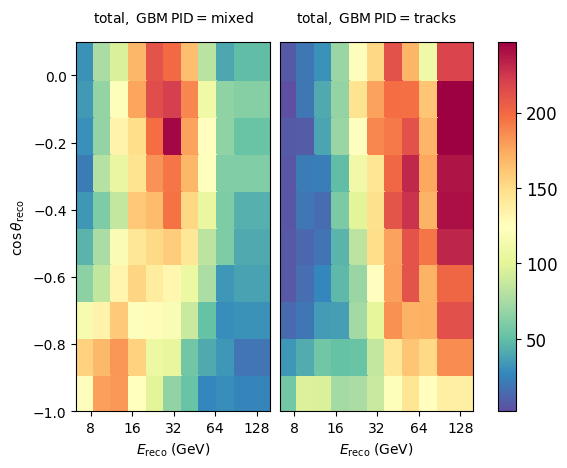

In [41]:
data.plot()

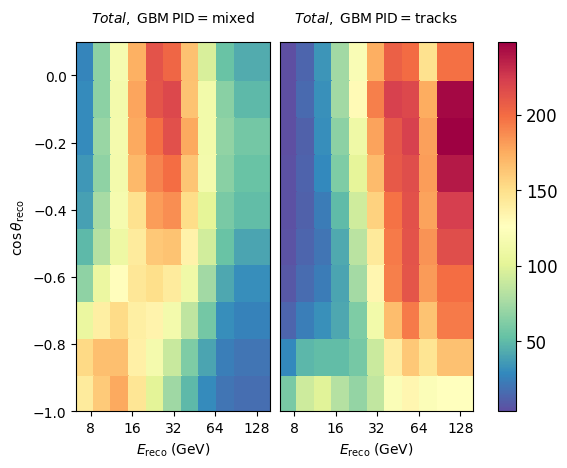

In [42]:
template = model.get_outputs(return_sum=True)
template.plot()

Let's see how good that fit looks like. We here construct signed mod_chi2 maps by hand.
You can see that after the fit, it improved considerably, and the distribution of chi2 values is now more uniform - not much features can be seen anymore.

[ WARNING] /home/jp/software/pisa/pisa/core/map.py:1909: FutureWarning: AffineScalarFunc.__abs__() is deprecated. It will be removed in a future release.
  'hist': np.abs(self.hist)



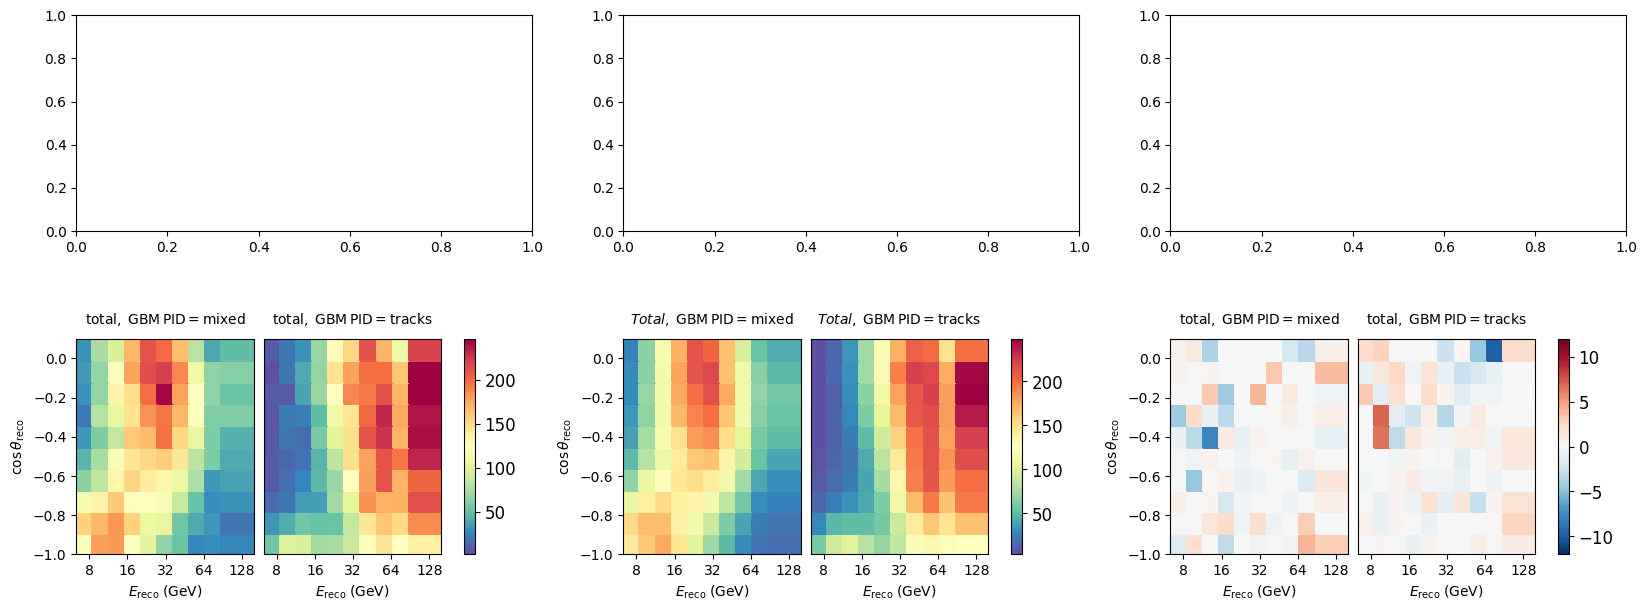

In [43]:
fig, ax = plt.subplots(2, 3, figsize=(20, 7))
plt.subplots_adjust(hspace=0.5)

bestfit = model.get_outputs(return_sum=True)

# data.plot(ax=ax[0,0],title="Data", full_ax=ax[0,0])
# nominal.plot(ax=ax[0,1], full_ax=ax[0,1], title="Nominal")
# diff = data - nominal
# (abs(diff)*diff/(nominal + unp.std_devs(nominal.hist['total']))).plot(ax=ax[0,2], full_ax=ax[0,2],
#                                                                       symm=True, title=r"signed $\chi^2$", vmin=-12, vmax=12)

data.plot(ax=ax[1,0], full_ax=ax[1,0], title="Data")
bestfit.plot(ax=ax[1,1], full_ax=ax[1,1], title="Bestfit")
diff = data - bestfit
(abs(diff)*diff/(bestfit + unp.std_devs(bestfit.hist['total']))).plot(ax=ax[1,2], full_ax=ax[1,2], 
                                                                      symm=True, title=r"signed $\chi^2$", vmin=-12, vmax=12)

When checking the chi2 value from the fitted model, you maybe see that it is around 113, while in the minimizer loop we saw it converged to 116. It is important to keep in mind that in the fit we had extended the metric with prior penalty terms. When we add those back we get the identical number as reported in the fit.

Evaluating other metrics just for fun:

In [44]:
for metric in pisa.utils.stats.ALL_METRICS:
    try:
        print('%s = %.3f'%(metric,data.metric_total(bestfit, metric)))
    except:
        print('%s failed'%metric)

llh = -110.036
conv_llh = -109.356
barlow_llh = -1877.105
mcllh_mean = -734.023
mcllh_eff = -733.990
generalized_poisson_llh failed
chi2 = 220.999
mod_chi2 = 219.570
[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/numpy/core/_methods.py:114: FutureWarning: AffineScalarFunc.__ge__() is deprecated. It will be removed in a future release.
  return ufunc(*args, out=out, **kwargs)

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/numpy/core/_methods.py:114: FutureWarning: AffineScalarFunc.__le__() is deprecated. It will be removed in a future release.
  return ufunc(*args, out=out, **kwargs)

correct_chi2 = 1100.278
weighted_chi2 failed


Adding prior penalty terms

## Storing the results to a file

Since the fit took a while, it might be useful to store the results to a file. (NB: in this example we use a temp file, but in real life you would of course just use a real pathname instead!)

In [45]:
import tempfile
temp = tempfile.NamedTemporaryFile(suffix='.json')
pisa.utils.fileio.to_file(result, temp.name)

[ WARNING] Directory "/tmp" already exists
[ WARNING] Overwriting file at '/tmp/tmpldlibmww.json'


To reload, we can read the file. But to get PISA objects back, they need to instantiated

In [46]:
result_reload = pisa.utils.fileio.from_file(temp.name)
bestfit_params = pisa.core.ParamSet(result_reload['params']).free
bestfit_params
temp.close()